In [1]:
import pandas as pd
import numpy as np
import seaborn as sns


df = pd.read_parquet("../data/processed/dvf_77_2025_filtre.parquet")
print(df.shape)

(13717, 14)


In [2]:
df["nombre_pieces_principales"].describe()

count    13717.000000
mean         3.653714
std          1.500975
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max         12.000000
Name: nombre_pieces_principales, dtype: float64

In [3]:
q1 = df["nombre_pieces_principales"].quantile(0.25)

q3 = df["nombre_pieces_principales"].quantile(0.75)

iqr = q3 - q1

borne_basse = q1 - 1.5*iqr

borne_haute = q3 + 1.5*iqr

print(f"Q1 (25%)        : {q1} ")
print(f"Q3 (75%)        : {q3} ")
print(f"IQR             : {iqr} ")
print(f"Borne basse     : {borne_basse} ")
print(f"Borne haute     : {borne_haute} ")

Q1 (25%)        : 3.0 
Q3 (75%)        : 5.0 
IQR             : 2.0 
Borne basse     : 0.0 
Borne haute     : 8.0 


In [4]:
repartition_pieces = df['nombre_pieces_principales'].value_counts().sort_index()

print(repartition_pieces)

nombre_pieces_principales
0.0        5
1.0      905
2.0     2315
3.0     3208
4.0     3496
5.0     2395
6.0      973
7.0      281
8.0       83
9.0       34
10.0      18
11.0       3
12.0       1
Name: count, dtype: int64


In [5]:
# 1. Définir les colonnes précises que vous souhaitez inspecter
colonnes_a_afficher = [ 'type_local', 'nombre_pieces_principales', 'valeur_fonciere','prix_m2', 'surface_reelle_bati','nb_dependances']

# 2. Filtrer les lignes où le nombre de pièces est égal à 0
condition_zero_piece = df['nombre_pieces_principales'] == 0
df_zero_piece = df.loc[condition_zero_piece, colonnes_a_afficher]

# 3. Afficher le nombre total de lignes concernées et un aperçu
print(f"Nombre de biens avec 0 pièce : {len(df_zero_piece)}")
print(df_zero_piece)

Nombre de biens avec 0 pièce : 5
        type_local  nombre_pieces_principales  valeur_fonciere      prix_m2  \
94          Maison                        0.0          80000.0  2222.222222   
3837        Maison                        0.0         199000.0  3980.000000   
9952   Appartement                        0.0          73000.0  2433.333333   
10919  Appartement                        0.0          64000.0  1939.393939   
11412  Appartement                        0.0          65000.0  1444.444444   

       surface_reelle_bati  nb_dependances  
94                    36.0               0  
3837                  50.0               1  
9952                  30.0               0  
10919                 33.0               0  
11412                 45.0               0  


In [6]:
lignes_a_supprimer = (df['nombre_pieces_principales'] == 0) 

df_nettoye = df[~lignes_a_supprimer].copy()

print(f"Nombre de lignes avant nettoyage : {len(df)}")
print(f"Nombre de lignes après nettoyage : {len(df_nettoye)}")
print(f"Nombre de lignes supprimées : {len(df) - len(df_nettoye)}")


Nombre de lignes avant nettoyage : 13717
Nombre de lignes après nettoyage : 13712
Nombre de lignes supprimées : 5


In [7]:
# 1. Grouper par nombre de pièces et calculer la moyenne du prix au m²
stats_par_piece  = df_nettoye.groupby('nombre_pieces_principales')['prix_m2'].agg(
    mediane="median",
    nb_ventes="count",
)


print(stats_par_piece )

                               mediane  nb_ventes
nombre_pieces_principales                        
1.0                        3850.000000        905
2.0                        3536.585366       2315
3.0                        3090.909091       3208
4.0                        2984.794701       3496
5.0                        2864.130435       2395
6.0                        2686.440678        973
7.0                        2524.647887        281
8.0                        2431.693989         83
9.0                        2179.629321         34
10.0                       2583.325677         18
11.0                       2541.935484          3
12.0                       1289.473684          1


<Axes: xlabel='nombre_pieces_principales', ylabel='prix_m2'>

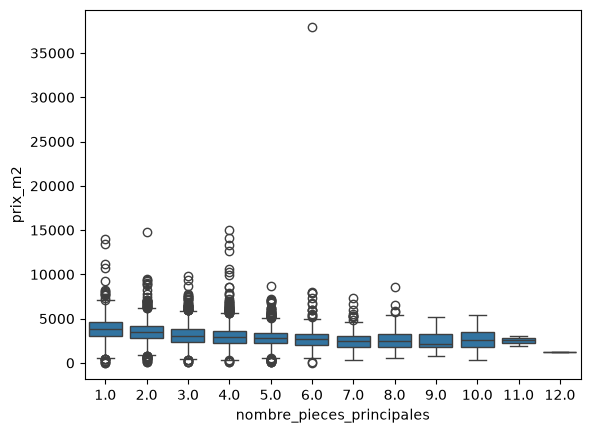

In [8]:
sns.boxplot(data=df_nettoye, x="nombre_pieces_principales", y="prix_m2")

In [9]:
# 1. Filtrer les lignes où le nombre de pièces est supérieur ou égal à 9
condition_grandes_pieces = df_nettoye['nombre_pieces_principales'] >= 9

# 2. Compter la répartition des types de locaux pour ces biens
repartition_types = df_nettoye.loc[condition_grandes_pieces, 'type_local'].value_counts()

print("--- Répartition des types de locaux pour 9 pièces et plus ---")
print(repartition_types)

--- Répartition des types de locaux pour 9 pièces et plus ---
type_local
Maison         54
Appartement     2
Name: count, dtype: int64


In [10]:
# 1. Définir les conditions combinées : type appartement ET 9 pièces ou plus
condition = (df_nettoye['type_local'] == 'Appartement') & (df_nettoye['nombre_pieces_principales'] >= 9)

# 2. Définir la liste des colonnes précises à afficher
colonnes_a_afficher = [
    'type_local', 
    'nombre_pieces_principales', 
    'surface_reelle_bati', 
    'valeur_fonciere', 
    'prix_m2'
]

# 3. Appliquer le filtre et sélectionner les colonnes avec .loc
df_appart_grands = df_nettoye.loc[condition, colonnes_a_afficher]

# 4. Afficher le nombre total trouvé et un aperçu
print(f"Nombre d'appartements trouvés avec 9 pièces ou plus : {len(df_appart_grands)}")
print(df_appart_grands)

Nombre d'appartements trouvés avec 9 pièces ou plus : 2
       type_local  nombre_pieces_principales  surface_reelle_bati  \
2585  Appartement                       10.0                173.0   
5440  Appartement                        9.0                206.0   

      valeur_fonciere      prix_m2  
2585         267000.0  1543.352601  
5440        1060000.0  5145.631068  


In [11]:
repartition_dependances = df_nettoye['nb_dependances'].value_counts().sort_index()

print(repartition_dependances)

nb_dependances
0     5727
1     5049
2     2381
3      458
4       79
5       10
6        3
7        2
10       1
18       1
19       1
Name: count, dtype: int64


In [12]:
condition = (df_nettoye['nb_dependances'] >= 6) 

# 2. Définir la liste des colonnes précises à afficher
colonnes_a_afficher = [
    'type_local', 
    'surface_reelle_bati', 
    'valeur_fonciere', 
    'prix_m2', 
    'nb_dependances',
    'surface_terrain_total'
]

# 3. Appliquer le filtre et sélectionner les colonnes avec .loc
df_dependances_elever = df_nettoye.loc[condition, colonnes_a_afficher]

# 4. Afficher le nombre total trouvé et un aperçu
print(df_dependances_elever)

        type_local  surface_reelle_bati  valeur_fonciere      prix_m2  \
1526        Maison                 68.0         199000.0  2926.470588   
3369        Maison                 66.0         115000.0  1742.424242   
3974   Appartement                108.0         255000.0  2361.111111   
4941        Maison                100.0         205000.0  2050.000000   
5377        Maison                126.0        1000000.0  7936.507937   
8689        Maison                 90.0         810000.0  9000.000000   
11292  Appartement                 78.0         181000.0  2320.512821   
12296       Maison                122.0         214000.0  1754.098361   

       nb_dependances  surface_terrain_total  
1526                7                 1017.0  
3369                6                 2366.0  
3974                6                    0.0  
4941               18                 7935.0  
5377               19                 4630.0  
8689               10                 2949.0  
11292        

In [13]:
# 1. Grouper par nombre de dependances et calculer la median du prix au m²
stats_par_dependances  = df_nettoye.groupby('nb_dependances')['prix_m2'].agg(
    mediane="median",
    nb_ventes="count",
)


print(stats_par_dependances )

                    mediane  nb_ventes
nb_dependances                        
0               2961.538462       5727
1               3274.509804       5049
2               3043.478261       2381
3               2788.205980        458
4               2750.000000         79
5               2219.318182         10
6               1754.098361          3
7               2623.491704          2
10              9000.000000          1
18              2050.000000          1
19              7936.507937          1


In [14]:
# 1. Optionnel : Filtrer pour s'assurer de ne prendre que les appartements et maisons
types_concernes = ['Appartement', 'Maison']
df_crosstab = df_nettoye[df_nettoye['type_local'].isin(types_concernes)].copy()

# 2. Créer le tableau croisé
tableau_croise = pd.crosstab(
    df_crosstab['type_local'], 
    df_crosstab['nb_dependances']
)

print(tableau_croise)

nb_dependances    0     1     2    3   4   5   6   7   10  18  19
type_local                                                       
Appartement      717  3107  1771  339  44   5   1   1   0   0   0
Maison          5010  1942   610  119  35   5   2   1   1   1   1


In [15]:
stats_par_type_et_dependances = df_nettoye.groupby(['type_local', 'nb_dependances'])['prix_m2'].agg(
    mediane="median",
    nb_ventes="count",
)

print(stats_par_type_et_dependances)

                                mediane  nb_ventes
type_local  nb_dependances                        
Appartement 0               3058.208955        717
            1               3487.179487       3107
            2               3125.000000       1771
            3               2906.250000        339
            4               2932.692308         44
            5               2450.000000          5
            6               2361.111111          1
            7               2320.512821          1
Maison      0               2951.611876       5010
            1               2934.431260       1942
            2               2754.700000        610
            3               2222.222222        119
            4               2321.428571         35
            5               1717.391304          5
            6               1748.261302          2
            7               2926.470588          1
            10              9000.000000          1
            18              205

In [16]:
# Obtenir le describe complet pour chaque type de local sur la surface du terrain
stats_terrain = df_nettoye.groupby('type_local')['surface_terrain_total'].describe()

print(stats_terrain)

              count        mean          std  min    25%    50%    75%  \
type_local                                                               
Appartement  5985.0   14.422222   190.830022  0.0    0.0    0.0    0.0   
Maison       7727.0  641.516371  1470.132580  0.0  256.0  444.0  657.0   

                 max  
type_local            
Appartement   6265.0  
Maison       82856.0  


In [17]:
# Définition des colonnes à afficher
colonnes_a_afficher = [
    'type_local', 
    'surface_reelle_bati', 
    'surface_terrain_total', 
    'valeur_fonciere', 
    'prix_m2'
]

# --- 1. Inspection des plus grands terrains pour les MAISONS ---
print("--- Top 10 des maisons avec la plus grande surface de terrain ---")
top_maisons_terrain = (
    df_nettoye.loc[df_nettoye['type_local'] == 'Maison', colonnes_a_afficher]
    .sort_values(by="surface_terrain_total", ascending=False)
    .head(10)
)
print(top_maisons_terrain.to_string())



# --- 2. Inspection des plus grands terrains pour les APPARTEMENTS ---
print("--- Top 10 des appartements avec la plus grande surface de terrain ---")
top_appart_terrain = (
    df_nettoye.loc[df_nettoye['type_local'] == 'Appartement', colonnes_a_afficher]
    .sort_values(by="surface_terrain_total", ascending=False)
    .head(10)
)
print(top_appart_terrain.to_string())

--- Top 10 des maisons avec la plus grande surface de terrain ---
     type_local  surface_reelle_bati  surface_terrain_total  valeur_fonciere      prix_m2
8348     Maison                111.0                82856.0        325000.00  2927.927928
9421     Maison                 85.0                26177.0        401400.00  4722.352941
5831     Maison                189.0                24188.0        640234.38  3387.483492
5542     Maison                200.0                23150.0        233365.00  1166.825000
817      Maison                189.0                22249.0        634581.00  3357.571429
3322     Maison                277.0                20512.0        536500.00  1936.823105
5062     Maison                198.0                19940.0        444000.00  2242.424242
4531     Maison                165.0                18733.0        634000.00  3842.424242
3783     Maison                 76.0                15974.0        156780.90  2062.906579
6433     Maison                 90

In [18]:
proportion_appart_terrain = (df_nettoye.loc[df_nettoye['type_local'] == 'Appartement', 'surface_terrain_total'] > 0).mean()

print(f"Proportion d'appartements avec un terrain > 0 : {proportion_appart_terrain}")

Proportion d'appartements avec un terrain > 0 : 0.03826232247284879


In [19]:
terrain_maisons = df_nettoye.loc[df_nettoye["type_local"] == "Maison", "surface_terrain_total"]
print(terrain_maisons.quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

0.05       0.00
0.10      95.00
0.25     256.00
0.50     444.00
0.75     657.00
0.90    1042.00
0.95    1621.40
0.99    4842.74
Name: surface_terrain_total, dtype: float64


                           mediane  nb_ventes
surface_terrain_total                        
(-1, 200]              2969.275499       1440
(200, 400]             3075.595238       1928
(400, 600]             3064.516129       2067
(600, 1000]            2670.454545       1459
(1000, 2000]           2357.505071        548
(2000, 100000]         2557.077626        285
                           mediane  nb_ventes
surface_terrain_total                        
(-0.001, 213.0]        2965.116279       1555
(213.0, 380.0]         3069.928362       1544
(380.0, 511.0]         3136.602871       1542
(511.0, 736.0]         2896.643783       1542
(736.0, 82856.0]       2484.047619       1544


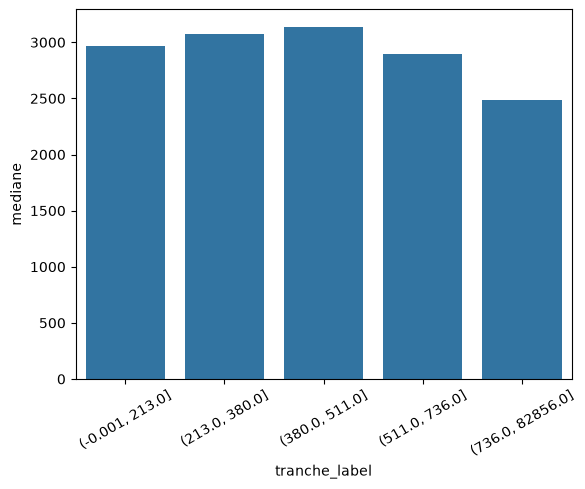

In [20]:
df_maisons = df_nettoye[df_nettoye['type_local'] == 'Maison'].copy()

tranches = pd.cut(df_maisons["surface_terrain_total"], bins=[-1, 200, 400, 600, 1000, 2000, 100000])

resultat_maisons = df_maisons.groupby(tranches)["prix_m2"].agg(
    mediane="median",
    nb_ventes="count",
)
print(resultat_maisons)

tranches_qcut = pd.qcut(df_maisons["surface_terrain_total"], q=5)

resultat_maisons_qcut = df_maisons.groupby(tranches_qcut)["prix_m2"].agg(
    mediane="median",
    nb_ventes="count",
)
print(resultat_maisons_qcut)


df_plot_cut = resultat_maisons_qcut.reset_index()
col_tranche_cut = df_plot_cut.columns[0] 
df_plot_cut['tranche_label'] = df_plot_cut[col_tranche_cut]

ax = sns.barplot(
    data=df_plot_cut,
    x='tranche_label',
    y='mediane',
   
)
ax.tick_params(axis="x", rotation=30)

## Sauvegarde du jeu de données

Le jeu de données filtré est enregistré dans un nouveau fichier, sans écraser `dvf_77_2025_filtre.parquet` : chaque notebook garde ainsi son entrée et sa sortie, et reste reproductible. La sélection explicite des colonnes d'origine (`df.columns`) garantit qu'aucune colonne temporaire créée pendant l'exploration ne se retrouve dans le fichier.

In [21]:
df_analyse = df_nettoye[df.columns]
df_analyse.to_parquet("../data/processed/dvf_77_2025_analyse.parquet", index=False)

df_verif = pd.read_parquet("../data/processed/dvf_77_2025_analyse.parquet")
print(df_verif.shape)

(13712, 14)


## Conclusion

Ce notebook part de `dvf_77_2025_filtre.parquet` (13 717 ventes) et explore trois caractéristiques du bien : le nombre de pièces, le nombre de dépendances et la surface de terrain.

**Nombre de pièces (`nombre_pieces_principales`)**

- Aucune valeur manquante, et une distribution régulière avec un pic à 4 pièces (3 496 ventes).
- 5 ventes affichent 0 pièce alors que leurs prix et surfaces sont réalistes : la valeur est très probablement non renseignée. Elles sont **supprimées** (13 717 → 13 712), car on n'impute pas une donnée inconnue et le coût est de 0,04 %.
- Le `prix_m2` médian baisse quand le nombre de pièces augmente (3 850 €/m² à 1 pièce, 2 180 €/m² à 9 pièces), cohérent avec l'effet de taille du notebook 04.
- Au-delà de 9 pièces, les effectifs (34, 18, 3 et 1 ventes) sont trop faibles pour que les médianes soient fiables. Ce sont presque uniquement des maisons (54 sur 56), et les 2 appartements concernés sont cohérents (17 à 23 m² par pièce). Regrouper ces catégories rares est un **choix de modélisation** : il est reporté, pour ne pas figer un seuil dans les données.

**Nombre de dépendances (`nb_dependances`)**

- 96 % des ventes ont 0 à 2 dépendances. Les 8 cas extrêmes (6 à 19 dépendances) sont 6 maisons rurales avec 2 400 à 7 900 m² de terrain, et 2 appartements (caves et parkings).
- **Limite connue :** la valeur des dépendances est incluse dans le prix, mais leur surface n'est pas comptée dans `surface_reelle_bati`, ce qui gonfle mécaniquement `prix_m2`. Ces ventes sont conservées et la limite est documentée, pour être réévaluée lors de la modélisation.
- **Variable de confusion :** la médiane globale monte de 0 à 1 dépendance (2 962 → 3 275 €/m²), mais cette hausse vient en grande partie de la composition (87 % de maisons à 0 dépendance, 62 % d'appartements à 1). En comparant à type égal, l'effet disparaît pour les maisons (2 952 → 2 934 €/m²) et persiste pour les appartements (3 058 → 3 487 €/m², environ +14 %), sans qu'on puisse départager un effet de qualité du bien d'un effet de valeur du parking inclus dans le prix.

**Surface de terrain (`surface_terrain_total`)**

- Pour les **appartements**, le terrain est celui de la résidence entière, identique pour tous les lots (6 265 m² pour trois appartements différents) : ce n'est pas une surface dont l'acheteur dispose. Seuls 3,8 % des appartements ont un terrain non nul.
- Pour les **maisons**, la médiane est de 444 m². La valeur maximale (82 856 m²) est une vraie propriété avec un `prix_m2` normal (2 928 €/m²), pas une erreur.
- Le `prix_m2` des maisons est stable jusqu'à 600 m² de terrain (autour de 3 000 €/m²), puis baisse (2 670 €/m² entre 600 et 1 000 m², 2 358 €/m² entre 1 000 et 2 000 m²). Ce lien négatif ne prouve pas que le terrain dévalorise la maison : les grands terrains sont typiques des zones rurales, où les prix sont plus bas.
- La neutralisation de cette variable pour les appartements est elle aussi un choix de modélisation, à tester plus tard.

**Enseignement méthodologique :** avant d'interpréter un lien entre deux variables, il faut isoler la variable de confusion (ici `type_local` et, probablement, la localisation). De même, les choix de transformation (regroupement, neutralisation) sont pris à la modélisation, pas figés dans les données sauvegardées.

**Bilan :** de 13 717 à **13 712 ventes**, enregistrées dans `data/processed/dvf_77_2025_analyse.parquet` (14 colonnes).

**Prochaine étape :** tester l'hypothèse que la localisation (communes rurales ou urbaines) explique une grande partie des écarts de `prix_m2` observés.